In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "diabetic_data.csv"

df = pd.read_csv(DATA_PATH)

df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [4]:
df.shape

(101766, 50)

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df["encounter_id"].duplicated().sum()

np.int64(0)

In [7]:
df["patient_nbr"].duplicated().sum()

np.int64(30248)

In [8]:
df["patient_nbr"].nunique()

71518

Proverom uocavamo duplikate redova za kolonu patient_nbr sto ukazuje da su neki pacijenti bili hospitalizovani vise puta.

---

In [9]:
MAPPING_PATH = PROJECT_ROOT / "data" / "raw" / "IDs_mapping.csv"

ids_mapping = pd.read_csv(MAPPING_PATH)

ids_mapping.head(20)

,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
5,6,NaN
6,7,Trauma Center
7,8,Not Mapped
8,NaN,NaN
9,discharge_disposition_id,description


In [10]:
ids_mapping["admission_type_id"]

0      1
1      2
2      3
3      4
4      5
      ..
62    22
63    23
64    24
65    25
66    26
Name: admission_type_id, Length: 67, dtype: object

In [11]:
ids_mapping.shape

(67, 2)

ids_mapping, tabela koja desifruje id-jeve glavne tabele. <br>
Potrebno je srediti strukturu tabele za bolje razumevanje.

In [12]:
def split_ids_mapping(ids_mapping):
    mappings = {}
    current_variable = ids_mapping.columns[0]
    current_rows = []

    for _, row in ids_mapping.iterrows():
        first_col = row.iloc[0]
        description = row.iloc[1]

        if pd.isna(first_col) and pd.isna(description):
            continue

        first_col_str = str(first_col).strip()
        description_str = str(description).strip()

        if first_col_str.endswith("_id") and description_str.lower() == "description":
            if current_rows:
                mappings[current_variable] = pd.DataFrame(current_rows)
                current_rows = []

            current_variable = first_col_str
            continue

        code = pd.to_numeric(first_col, errors="coerce")

        if pd.notna(code):
            current_rows.append({
                current_variable: int(code),
                "description": description
            })

    if current_rows:
        mappings[current_variable] = pd.DataFrame(current_rows)

    return mappings

In [13]:
ids_mappings = split_ids_mapping(ids_mapping)

In [14]:
admission_type_mapping = ids_mappings["admission_type_id"]
discharge_disposition_mapping = ids_mappings["discharge_disposition_id"]
admission_source_mapping = ids_mappings["admission_source_id"]

In [15]:
admission_type_mapping

,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
5,6,NaN
6,7,Trauma Center
7,8,Not Mapped


In [16]:
discharge_disposition_mapping

,discharge_disposition_id,description
0,1,Discharged to home
1,2,Discharged/transferred to another short term h...
2,3,Discharged/transferred to SNF
3,4,Discharged/transferred to ICF
4,5,Discharged/transferred to another type of inpa...
5,6,Discharged/transferred to home with home healt...
6,7,Left AMA
7,8,Discharged/transferred to home under care of H...
8,9,Admitted as an inpatient to this hospital
9,10,Neonate discharged to another hospital for neo...


Ova tabela nam pokazuje ishod otpusta pacijenata. <br>
Treba izbaciti kategorije koje nisu prediktivne za pitanje da li ce pacijent biti ponovo primljen u bolnicu u roku od 30 dana ili koje mogu vestacki poboljsati performanse modela. <br>
Exipred - preminuli pacijent. (nikada nece biti ponovo hospitalizovan, model bi vestacki imao lak signal) <br>
Hospice - pacijent je otpusten na specijalizovanu negu, ne ocekuje se ponovno lecenje u bolnici.

In [17]:
admission_source_mapping

,admission_source_id,description
0,1,Physician Referral
1,2,Clinic Referral
2,3,HMO Referral
3,4,Transfer from a hospital
4,5,Transfer from a Skilled Nursing Facility (SNF)
5,6,Transfer from another health care facility
6,7,Emergency Room
7,8,Court/Law Enforcement
8,9,Not Available
9,10,Transfer from critial access hospital


In [18]:
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"

admission_type_mapping.to_csv(
    TABLES_DIR / "admission_type_mapping.csv",
    index=False
)

discharge_disposition_mapping.to_csv(
    TABLES_DIR / "discharge_disposition_mapping.csv",
    index=False
)

admission_source_mapping.to_csv(
    TABLES_DIR / "admission_source_mapping.csv",
    index=False
)

In [19]:
sensitive_discharge_ids = [11, 13, 14, 19, 20, 21]

df = df[
    ~df["discharge_disposition_id"].isin(sensitive_discharge_ids)
].copy()

df.shape

(99343, 50)

---

Proveravamo kategorije kako bismo identifikovali sve oznake koje predstavljaju nedostajuce ili nepoznate vrednosti i zamenili ih vrednoscu NaN ili obradili na drugi nacin.

In [20]:
object_columns = df.select_dtypes(include="object").columns

for col in object_columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).head())


race
race
Caucasian          74220
AfricanAmerican    18772
?                   2234
Hispanic            2017
Other               1472
Name: count, dtype: int64

gender
gender
Female             53454
Male               45886
Unknown/Invalid        3
Name: count, dtype: int64

age
age
[70-80)    25331
[60-70)    22059
[50-60)    17060
[80-90)    16434
[40-50)     9607
Name: count, dtype: int64

weight
weight
?            96218
[75-100)      1312
[50-75)        867
[100-125)      617
[125-150)      143
Name: count, dtype: int64

payer_code
payer_code
?     39398
MC    31333
HM     6195
SP     4941
BC     4601
Name: count, dtype: int64

medical_specialty
medical_specialty
?                         48616
InternalMedicine          14237
Emergency/Trauma           7419
Family/GeneralPractice     7252
Cardiology                 5279
Name: count, dtype: int64

diag_1
diag_1
428    6663
414    6550
786    4015
410    3448
486    3383
Name: count, dtype: int64

diag_2
diag_2
276    6589
428   

Obrisacemo Unknown/Invalid instance koje pripadaju ovoj kategoriji za atribut gender jer ih je samo 3, i nije potrebno da model kasnije to tumaci kao posebnu kolonu.

In [21]:
df = df[df["gender"] != "Unknown/Invalid"].copy()

In [22]:
df = df.replace("?", np.nan)

In [23]:
columns_summary = pd.DataFrame({
    "column_name": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "unique_values": df.nunique(dropna=True).values,
    "missing_count": df.isna().sum().values,
    "missing_percent": (df.isna().sum().values / len(df) * 100).round(2)
}).sort_values(by="missing_percent", ascending=False)

columns_summary

,column_name,dtype,unique_values,missing_count,missing_percent
5,weight,object,9,96215,96.85
22,max_glu_serum,object,3,94188,94.81
23,A1Cresult,object,3,82506,83.05
11,medical_specialty,object,72,48614,48.94
10,payer_code,object,17,39397,39.66
2,race,object,5,2232,2.25
20,diag_3,object,786,1419,1.43
19,diag_2,object,747,356,0.36
18,diag_1,object,715,20,0.02
1,patient_nbr,int64,69987,0,0.00


In [24]:
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"

columns_summary.to_csv(TABLES_DIR / "columns_summary.csv", index=False)

---

Provera raspodele i konstrukcija izlazne promenljive.

In [25]:
df["readmitted"].value_counts()

readmitted
NO     52524
>30    35502
<30    11314
Name: count, dtype: int64

In [26]:
df["readmitted"].value_counts(normalize=True) * 100

readmitted
NO     52.872962
>30    35.737870
<30    11.389169
Name: proportion, dtype: float64

In [27]:
df["target_readmitted_30"] = (df["readmitted"] == "<30").astype(int)

target_distribution = df["target_readmitted_30"].value_counts().reset_index()
target_distribution.columns = ["target_readmitted_30", "count"]
target_distribution["percent"] = (
    target_distribution["count"] / len(df) * 100
).round(2)

target_distribution.to_csv(TABLES_DIR / "target_distribution.csv", index=False)

target_distribution

,target_readmitted_30,count,percent
0,0,88026,88.61
1,1,11314,11.39


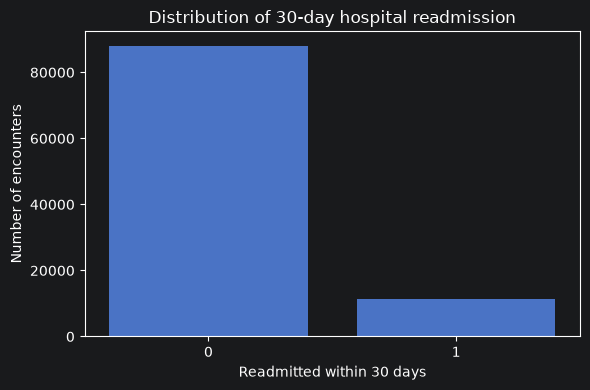

In [28]:
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="target_readmitted_30")
plt.title("Distribution of 30-day hospital readmission")
plt.xlabel("Readmitted within 30 days")
plt.ylabel("Number of encounters")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "target_distribution.png", dpi=300, bbox_inches="tight")

plt.show()

In [29]:
df.shape

(99340, 51)

---

In [30]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

df.to_csv(PROCESSED_DIR / "basic_clean.csv", index=False)

Glavna tabela ima 99340 redova i 51 kolonu. <br>
Skup podataka je nebalansiran, svega 11.39% pacijenata je ponovo hospitalizovano nakon 30 dana. <br>
Nedostajuce vrednosti, enkoding i selekcija atributa ce biti posebno obradjene.

Sledeca funkcija za dati atribut racuna kolika je stopa readmisije u roku od 30 dana za svaku njegovu vrednost ili kategoriju. <br>
Proverava da li atribut ima nedostajuce vrednosti i NaN pretvara u posebnu kategoriju, grupise podatke po vrednostima atributa i racuna prosek targeta za svaku grupu, velicinu grupe, i na kraju sortira opadajuce prema stopi readmisije.

In [31]:
def readmission_rate_table(df, feature, target_col="target_readmitted_30"):
    temp = df[[feature, target_col]].copy()

    if temp[feature].isna().any():
        temp[feature] = temp[feature].astype("object")
        temp.loc[temp[feature].isna(), feature] = "Missing"

    summary = (
        temp.groupby(feature, observed=True)[target_col]
        .agg(readmission_rate="mean", count="count")
        .reset_index()
    )

    summary["readmission_rate_percent"] = (
        summary["readmission_rate"] * 100
    ).round(2)

    return summary.sort_values("readmission_rate_percent", ascending=False)

Sada samo za neke od atributa proveravamo readmission rate.

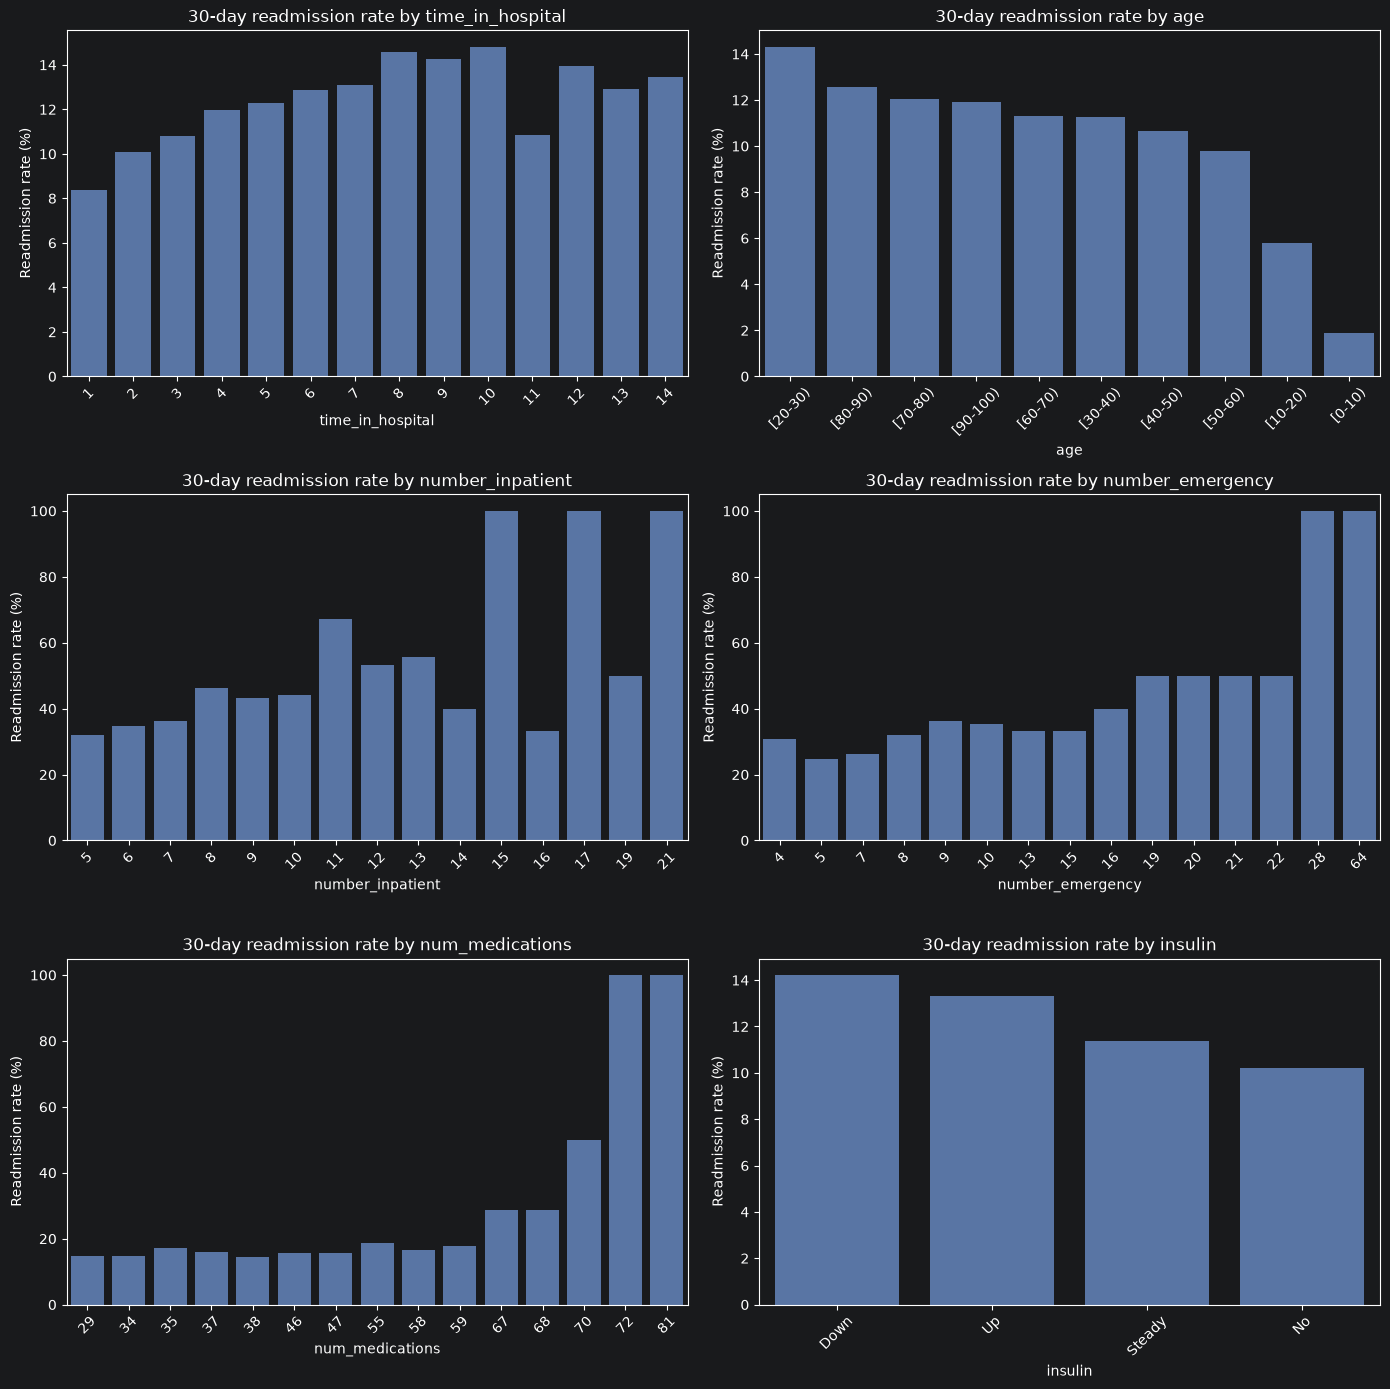

In [32]:
features_to_check = [
    "time_in_hospital",
    "age",
    "number_inpatient",
    "number_emergency",
    "num_medications",
    "insulin"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for ax, feature in zip(axes, features_to_check):
    summary = readmission_rate_table(df, feature)

    if summary.shape[0] > 15:
        summary = summary.head(15)

    sns.barplot(
        data=summary,
        x=feature,
        y="readmission_rate_percent",
        color="#4C72B0",
        ax=ax
    )

    ax.set_title(f"30-day readmission rate by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Readmission rate (%)")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "readmission_rate_selected_features.png", dpi=300, bbox_inches="tight")
plt.show()

Moze se uociti da su pacijenti sa duzim boravkom u bolnici, vecim brojem prethodnih hospitalizacija i hitnih prijema povezani sa vecom stopom readmisije sto ukazuje da ovi atributi mogu biti znacajni prediktori readmisije. <br>
Kod atributa insulin uocena je najveca stopa readmisije kod pacijenata kod kojih je terapija smanjena ili povecana. <br>
Najmladja starosna grupa ima najnizu stopu readmisije. <br>
Medjutim pojedine atribute poput number_inpatient ili num_medications treba imati u vidu da cine manje zastupljene grupe u skupu podataka, te visoka stopa readmisije moze biti posledica malog broja pacijenata a ne stvarnog obrasca.<br>
Takodje, analiza pojedinacnih atributa ne mora u potpunosti da odrazava njihov znacaj na predvidjanje readmisije jer modeli masinskog ucenja mogu prepoznati obrasce i interakcije izmedju vise atributa.